In [1]:
import os
import pandas as pd
import kagglehub

# 1. Kagglehub orqali datasetni yuklab olamiz
path = kagglehub.dataset_download(
    "mathchi/online-retail-ii-data-set-from-ml-repository"
)
print("Path to dataset files:", path)

# 2. Yuklangan papka ichida qanday fayllar borligini tekshiramiz
files = os.listdir(path)
print("Fayllar ro'yxati:", files)

# 3. Faylni Pandas yordamida o'qimiz (fayl nomiga qarab o'zgartirasiz, masalan: .csv yoki .xlsx)
# Odatda bu datasetda .csv yoki .xlsx formatida bo'ladi
file_path = os.path.join(path, files[0])  # Birinchi topilgan faylni oladi

if file_path.endswith('.csv'):
  df = pd.read_csv(file_path, encoding='ISO-8859-1')
else:
  df = pd.read_excel(file_path)

print("Ma'lumotlar muvaffaqiyatli yuklandi! Qatorlar soni:", df.shape)
df.head()

100%|██████████| 57.5M/57.5M [00:00<00:00, 104MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/mathchi/online-retail-ii-data-set-from-ml-repository/versions/3
Fayllar ro'yxati: ['Year 2009-2010.csv', 'Year 2010-2011.csv', 'online_retail_II.xlsx']
Ma'lumotlar muvaffaqiyatli yuklandi! Qatorlar soni: (525461, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,12/1/2009 7:45,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,12/1/2009 7:45,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,12/1/2009 7:45,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,12/1/2009 7:45,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,12/1/2009 7:45,1.25,13085.0,United Kingdom


In [6]:
import os
import pandas as pd
import numpy as np
import datetime as dt
import sqlite3

# Kagglehub yuklagan papka va fayl nomini birlashtiramiz
file_path = os.path.join(
    path, 'Year 2009-2010.csv'
)  # yoki 'Year 2010-2011.csv'

# Endi faylni bemalol o'qiymiz
df = pd.read_csv(file_path, encoding='ISO-8859-1')

# Data haqida umumiy ma'lumot
print("Ma'lumotlar o'lchami:", df.shape)
df.head()

Ma'lumotlar o'lchami: (525461, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,12/1/2009 7:45,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,12/1/2009 7:45,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,12/1/2009 7:45,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,12/1/2009 7:45,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,12/1/2009 7:45,1.25,13085.0,United Kingdom


In [8]:
import sqlite3

# 1. Ustun nomidagi bo'sh joyni olib tashlaymiz (Customer ID -> CustomerID)
if 'Customer ID' in df.columns:
  df = df.rename(columns={'Customer ID': 'CustomerID'})

# 2. Pandas DataFrame-ni SQLite xotira bazasiga yuklaymiz
conn = sqlite3.connect(':memory:')
df.to_sql('online_retail', conn, index=False, if_exists='replace')

# 3. SQL so'rovi (endi ustun nomi toza: CustomerID)
sql_query = """
WITH MaxDate AS (
    SELECT MAX(InvoiceDate) as max_date FROM online_retail
)
SELECT
    CustomerID,
    CAST((JULIANDAY((SELECT max_date FROM MaxDate)) - JULIANDAY(MAX(InvoiceDate))) AS INTEGER) AS Recency,
    COUNT(DISTINCT Invoice) AS Frequency,
    ROUND(SUM(TotalSum), 2) AS Monetary
FROM online_retail
GROUP BY CustomerID
"""

rfm_table = pd.read_sql_query(sql_query, conn)

print("Muvaffaqiyatli bajarildi! RFM jadvali (dastlabki 5 ta qator):")
display(rfm_table.head())

Muvaffaqiyatli bajarildi! RFM jadvali (dastlabki 5 ta qator):


,CustomerID,Recency,Frequency,Monetary
0,12346.0,164,11,372.86
1,12347.0,2,2,1323.32
2,12348.0,73,1,222.16
3,12349.0,42,3,2671.14
4,12351.0,10,1,300.93


In [9]:
# 1. R, F, M qiymatlariga 1 dan 5 gacha ball beramiz (Quantiles yordamida)
# Eslatma: Recency bo'yicha kam kun o'tgani yaxshi (shuning uchun ball teskari beriladi: 5 - eng yaqinda xarid qilgan)
rfm_table['R_Score'] = pd.qcut(
    rfm_table['Recency'], 5, labels=[5, 4, 3, 2, 1]
)

# Frequency va Monetary bo'yicha ko'p bo'lgani yaxshi (shuning uchun 1 dan 5 gacha)
# Agar Frequency qiymatlari bir xil takrorlanib qolsa, duplicates='drop' xatolikni oldini oladi
rfm_table['F_Score'] = pd.qcut(
    rfm_table['Frequency'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]
)
rfm_table['M_Score'] = pd.qcut(rfm_table['Monetary'], 5, labels=[1, 2, 3, 4, 5])

# 2. Ballarni matn ko'rinishida birlashtiramiz (masalan: '555' eng zo'r mijoz)
rfm_table['RFM_Score'] = (
    rfm_table['R_Score'].astype(str)
    + rfm_table['F_Score'].astype(str)
    + rfm_table['M_Score'].astype(str)
)

# 3. Mijozlarga biznes segment nomlarini beramiz
def segment_customer(row):
  # Agar R va F/M ballari baland bo'lsa - VIP
  if row['R_Score'] >= 4 and row['F_Score'] >= 4:
    return 'VIP / Sodiq mijozlar'
  # Agar Recency past bo'lib, lekin oldin ko'p pul sarflagan bo'lsa - Yo'qolish xavfidagilar
  elif row['R_Score'] <= 2 and row['M_Score'] >= 4:
    return "Yo'qolish xavfidagi VIP"
  # Yangi mijozlar (yaqinda kelgan, lekin hali kam xarid qilgan)
  elif row['R_Score'] >= 4 and row['F_Score'] <= 2:
    return 'Yangi mijozlar'
  # O'rtacha mijozlar
  elif row['R_Score'] == 3 and row['F_Score'] == 3:
    return 'O\'rtacha mijozlar'
  else:
    return 'Boshqa / Uxlayotgan mijozlar'


rfm_table['Segment'] = rfm_table.apply(segment_customer, axis=1)

# Natijani tekshiramiz
print('Segmentlar bo\'yicha mijozlar soni:')
print(rfm_table['Segment'].value_counts())

rfm_table.head(10)

Segmentlar bo'yicha mijozlar soni:
Segment
Boshqa / Uxlayotgan mijozlar    2280
VIP / Sodiq mijozlar            1105
Yangi mijozlar                   367
Yo'qolish xavfidagi VIP          353
O'rtacha mijozlar                207
Name: count, dtype: int64


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
0,12346.0,164,11,372.86,2,5,2,252,Boshqa / Uxlayotgan mijozlar
1,12347.0,2,2,1323.32,5,2,4,524,Yangi mijozlar
2,12348.0,73,1,222.16,2,1,1,211,Boshqa / Uxlayotgan mijozlar
3,12349.0,42,3,2671.14,3,3,5,335,O'rtacha mijozlar
4,12351.0,10,1,300.93,5,1,2,512,Yangi mijozlar
5,12352.0,10,2,343.80,5,2,2,522,Yangi mijozlar
6,12353.0,43,1,317.76,3,1,2,312,Boshqa / Uxlayotgan mijozlar
7,12355.0,202,1,488.21,1,1,2,112,Boshqa / Uxlayotgan mijozlar
8,12356.0,15,3,3562.25,4,3,5,435,Boshqa / Uxlayotgan mijozlar
9,12357.0,23,2,12079.99,4,2,5,425,Yangi mijozlar


'output_file' fayli muvaffaqiyatli saqlandi!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

/tmp/ipykernel_1218/754765392.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


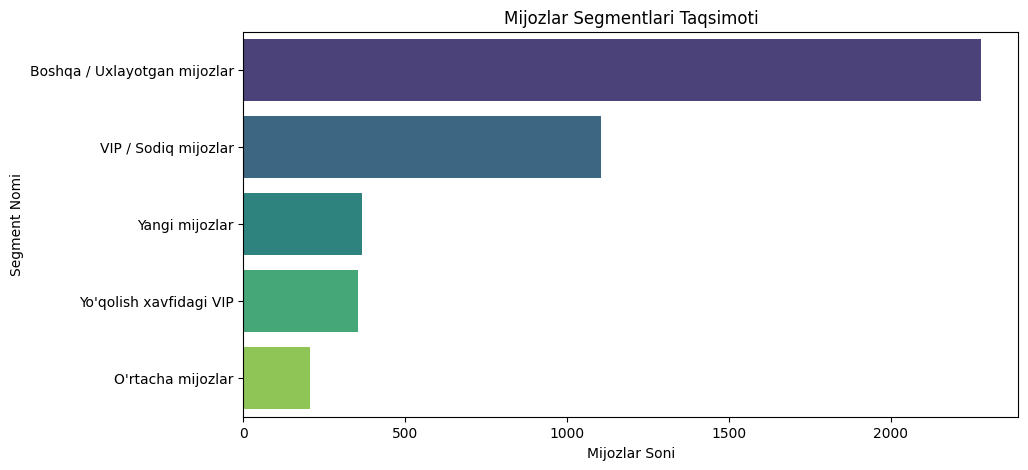

In [11]:
# 1. Tayyor RFM jadvalini CSV fayl sifatida saqlaymiz
output_file = 'rfm_customer_segments.csv'
rfm_table.to_csv(output_file, index=False)

print(f"'output_file' fayli muvaffaqiyatli saqlandi!")

# 2. Faylni kompyuterga yuklab olish uchun (Colab uchun maxsus buyruq)
from google.colab import files

files.download(output_file)

# 3. Qaysi segmentda qancha mijoz borligini vizual ko'rish uchun kichik grafik chizamiz
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))
sns.countplot(
    data=rfm_table,
    y='Segment',
    order=rfm_table['Segment'].value_counts().index,
    palette='viridis',
)
plt.title('Mijozlar Segmentlari Taqsimoti')
plt.xlabel('Mijozlar Soni')
plt.ylabel('Segment Nomi')
plt.show()